<a href="https://colab.research.google.com/github/masumeaslanii/ML2026/blob/main/The_Fourth_Session.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [52]:
import numpy as np
import time
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader, Subset
from torchvision import transforms, datasets

# What do we do for implementing 2D CNN on our Dataset?

* Connecting to our Drive
* Loading our dataset
* Creating batch sets
* Definig device
* Designing our CNN model
* Train and validation loop
* Saving and Loading our model
* predicting on unseen data

> Note: This library `google.colab` is specific to Google Colab and cannot be used directly in local environments such as VS Code.

In [53]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Data Preprocessing and Transformations

In this section, we define preprocessing operations to prepare images before feeding them into the CNN model.

- **RandomCrop:** Randomly crops a 32×32 region after adding 4 pixels of padding around the image. It helps the model generalize better by exposing it to objects at slightly different positions, making it more robust to small spatial shifts and reducing overfitting.
- **RandomHorizontalFlip:** Randomly flips images horizontally with a probability of 0.5.
- **ToTensor**: Converts the image into a PyTorch tensor, changes its dimension order from `(H, W, C)` to `(C, H, W)`, and scales pixel values from `[0, 255]` to `[0, 1]`.
- **Normalization:** Scales pixel values from [0, 1] to approximately [-1, 1] using the specified mean and standard deviation.

We use `transforms.Compose()` to combine multiple transformations into a single pipeline.

**Training Transform:** Applies data augmentation (RandomCrop and RandomHorizontalFlip), followed by tensor conversion and normalization.

**Test Transform:** Applies only tensor conversion and normalization, without data augmentation. This allows us to evaluate the model on unmodified images and measure its performance more realistically.
> Data Augmentation Increases the diversity of training samples and helps the model generalize better to unseen data. It is typically applied only to training data, not validation or test data.

> Note: Since CIFAR images have three color channels (RGB), mean and standard deviation each contain three values. Using `0.5` for all three channels is a simple and common normalization choice, but these are not necessarily the dataset's actual statistics.

In [54]:
mean, std = (0.5, 0.5, 0.5), (0.5, 0.5, 0.5)

train_transform = transforms.Compose([transforms.RandomCrop(32, padding= 4),
                                      transforms.RandomHorizontalFlip(),
                                      transforms.ToTensor(),
                                      transforms.Normalize(mean= mean, std= std)])


test_transform = transforms.Compose([transforms.ToTensor(),
                                    transforms.Normalize(mean= mean, std= std)])

## Loading CIFAR-100 Dataset

In this section, we load the CIFAR-100 dataset using `torchvision.datasets.CIFAR100()`.

- **DATA_DIR:** Specifies the directory where the dataset is stored.
- **Training Dataset:** Loads the 50,000 training images using `train=True` and applies training transformations, including data augmentation.
- **Validation Dataset:** Loads the same 50,000 training images using `train=True`, but applies only tensor conversion and normalization. We will later use `Subset` to select 5,000 images for validation.
- **Test Dataset:** Loads the 10,000 test images using `train=False`, without data augmentation. These images are reserved for final model evaluation.

**Note:** CIFAR-100 provides two original splits: 50,000 training images and 10,000 test images. It does not include a separate validation set, so we create one from the training data.

### Dataset Summary

| Dataset | Images | Augmentation | Purpose |
|---|---:|---|---|
| Training | 50,000 initially | Yes | Model training |
| Validation | 5,000 selected | No | Model evaluation during development |
| Test | 10,000 | No | Final model evaluation |

In [55]:
DATA_DIR= '/content/drive/MyDrive/CIFAR100_Dataset'

traindata = datasets.CIFAR100(root= DATA_DIR,
                              train= True,
                              download= False,
                              transform= train_transform)

validationdata = datasets.CIFAR100(root= DATA_DIR,
                              train= True,
                              download= False,
                              transform= test_transform)

testdata = datasets.CIFAR100(root= DATA_DIR,
                              train= False,
                              download= False,
                              transform= test_transform)

In [56]:
traindata

Dataset CIFAR100
    Number of datapoints: 50000
    Root location: /content/drive/MyDrive/CIFAR100_Dataset
    Split: Train
    StandardTransform
Transform: Compose(
               RandomCrop(size=(32, 32), padding=4)
               RandomHorizontalFlip(p=0.5)
               ToTensor()
               Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
           )

In [57]:
validationdata

Dataset CIFAR100
    Number of datapoints: 50000
    Root location: /content/drive/MyDrive/CIFAR100_Dataset
    Split: Train
    StandardTransform
Transform: Compose(
               ToTensor()
               Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
           )

In [58]:
testdata

Dataset CIFAR100
    Number of datapoints: 10000
    Root location: /content/drive/MyDrive/CIFAR100_Dataset
    Split: Test
    StandardTransform
Transform: Compose(
               ToTensor()
               Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
           )

- `traindata[49999]`: Retrieves the sample at index `49999`, returning a tuple `(image, label)`.
- `traindata[49999][0]`: Retrieves the image.
- `traindata[49999][1]`: Retrieves the corresponding class label.
- `type(traindata[49999][0])`: Returns `torch.Tensor`.

**Why?** Because `ToTensor()` converts the image into a PyTorch Tensor.

**Note:** Random transformations are applied every time a sample is accessed, so the same image may look slightly different each time.

In [59]:
type(traindata[49999][0])

torch.Tensor

`traindata.targets` Returns the labels of all training images. CIFAR-100 has 100 classes, so labels range from `0` to `99`.
- `train_label[49999]` Returns the label of the sample at index `49999`.

In [60]:
train_label = traindata.targets

`traindata.data` Returns the original images without applying any transformations.
- Unlike `traindata[index]`, it does not apply the assigned transform.

In [61]:
train_image = traindata.data

In [62]:
train_image

array([[[[255, 255, 255],
         [255, 255, 255],
         [255, 255, 255],
         ...,
         [195, 205, 193],
         [212, 224, 204],
         [182, 194, 167]],

        [[255, 255, 255],
         [254, 254, 254],
         [254, 254, 254],
         ...,
         [170, 176, 150],
         [161, 168, 130],
         [146, 154, 113]],

        [[255, 255, 255],
         [254, 254, 254],
         [255, 255, 255],
         ...,
         [189, 199, 169],
         [166, 178, 130],
         [121, 133,  87]],

        ...,

        [[148, 185,  79],
         [142, 182,  57],
         [140, 179,  60],
         ...,
         [ 30,  17,   1],
         [ 65,  62,  15],
         [ 76,  77,  20]],

        [[122, 157,  66],
         [120, 155,  58],
         [126, 160,  71],
         ...,
         [ 22,  16,   3],
         [ 97, 112,  56],
         [141, 161,  87]],

        [[ 87, 122,  41],
         [ 88, 122,  39],
         [101, 134,  56],
         ...,
         [ 34,  36,  10],
        

array([[[ 31,  67, 122],
        [ 30,  68, 124],
        [ 31,  69, 126],
        ...,
        [ 32,  70, 129],
        [ 32,  70, 125],
        [ 32,  69, 122]],

       [[ 29,  68, 126],
        [ 28,  69, 128],
        [ 30,  69, 130],
        ...,
        [ 32,  70, 131],
        [ 32,  69, 127],
        [ 31,  69, 124]],

       [[ 30,  67, 126],
        [ 29,  68, 128],
        [ 30,  69, 130],
        ...,
        [ 32,  72, 132],
        [ 31,  70, 130],
        [ 30,  69, 127]],

       ...,

       [[ 39,  41,  76],
        [ 38,  42,  76],
        [ 38,  44,  78],
        ...,
        [ 39,  44,  79],
        [ 38,  42,  77],
        [ 39,  41,  76]],

       [[ 40,  39,  73],
        [ 39,  40,  74],
        [ 39,  41,  76],
        ...,
        [ 39,  41,  76],
        [ 40,  41,  74],
        [ 40,  39,  73]],

       [[ 40,  39,  70],
        [ 40,  39,  71],
        [ 40,  39,  72],
        ...,
        [ 41,  38,  72],
        [ 39,  38,  69],
        [ 40,  37,  67]]], dtype=uint8)
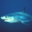

In [63]:
train_image[49999]

In [64]:
train_image[49999].shape

(32, 32, 3)

In [65]:
type(train_image[49999])

numpy.ndarray

array([[[141, 134, 115],
        [167, 160, 142],
        [161, 154, 137],
        ...,
        [ 59,  49,  38],
        [ 44,  34,  23],
        [ 80,  70,  60]],

       [[107,  99,  85],
        [146, 139, 121],
        [153, 147, 124],
        ...,
        [ 40,  30,  18],
        [103,  94,  81],
        [165, 155, 143]],

       [[ 71,  64,  49],
        [112, 105,  87],
        [120, 114,  91],
        ...,
        [ 96,  87,  72],
        [154, 145, 130],
        [180, 170, 155]],

       ...,

       [[119, 112,  94],
        [ 92,  86,  68],
        [ 79,  72,  54],
        ...,
        [147, 138, 121],
        [ 95,  86,  69],
        [ 59,  50,  33]],

       [[130, 122, 104],
        [114, 107,  89],
        [ 84,  77,  59],
        ...,
        [ 71,  62,  45],
        [ 52,  43,  26],
        [ 81,  72,  55]],

       [[141, 133, 115],
        [122, 115,  98],
        [106,  99,  81],
        ...,
        [ 66,  57,  40],
        [ 98,  89,  72],
        [140, 131, 114]]], dtype=uint8)
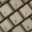

In [66]:
train_image[4999]

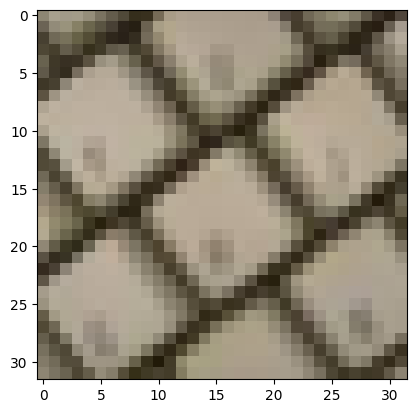

In [67]:
plt.imshow(train_image[4999])

In [68]:
train_image.shape

(50000, 32, 32, 3)

In [69]:
train_image.shape[0]

50000

## Splitting Training and Validation Data

We split the original 50,000 training images into:
- **Training:** 45,000 samples
- **Validation:** 5,000 samples

**Creating a Generator:**
- `torch.Generator()` Creates a random number generator.
- `manual_seed(42)` Ensures reproducibility by generating the same random sequence across runs under the same conditions.

**Generating Random Indices:**
- `torch.randperm()` Generates a random permutation of integers from `0` to `49,999`.
- `generator=generator` Uses our predefined generator and seed.

**Selecting Training Indices:**
- `indices[:45000]` Selects the first 45,000 indices.
- `.tolist()` Converts the Tensor into a Python list.

**Selecting Validation Indices:**
- `indices[45000:]` Selects the remaining 5,000 indices.
- `.tolist()` Converts them into a Python list.

> **Note:** Both subsets are randomly selected without overlap, ensuring that each sample belongs to either the training or validation set.

In [70]:
generator = torch.Generator().manual_seed(42)
indices= torch.randperm(train_image.shape[0], generator= generator)
indices

tensor([37542, 44491,   216,  ..., 40730, 25847, 33082])

In [71]:
train_indices = indices[:45000].tolist()
validaion_indices = indices[45000:].tolist()
type(train_indices)

list

## Creating Training and Validation Subsets

We use `Subset()` to create two smaller datasets from the original datasets using the selected indices.

- **Training Subset:** Selects 45,000 samples from `traindata`, applying `train_transform` (including data augmentation).
- **Validation Subset:** Selects 5,000 samples from `validationdata`, applying `test_transform` (without data augmentation).

> **Important:** The validation subset must be created from `validationdata`, not `traindata`, to ensure that random data augmentation is not applied during validation.

In [72]:
train_data = Subset(traindata, train_indices)
val_data = Subset(validationdata, validaion_indices)

## Creating DataLoaders

`DataLoader()` divides datasets into smaller batches for efficient training and evaluation.

- **batch_size=128:** Processes 128 images per batch. The training set contains 352 batches per epoch.
- **shuffle=True:** Randomly changes the sample order in each epoch to prevent learning from a fixed data order.

**TestLoader:**
Loads 10,000 test images in batches of 128. `shuffle=False` keeps their order unchanged.

**ValidationLoader:**
Loads 5,000 validation images in batches of 128, also with `shuffle=False`.

| DataLoader | Samples | Shuffle |
|---|---:|---|
| TrainLoader | 45,000 | True |
| ValidationLoader | 5,000 | False |
| TestLoader | 10,000 | False |

In [73]:
TrainLoader = DataLoader(train_data, batch_size= 128, shuffle= True)
TestLoader = DataLoader(testdata, batch_size= 128, shuffle= False)
ValidationLoader = DataLoader(val_data, batch_size= 128, shuffle= False)